In [577]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
plt.style.use("seaborn-v0_8-whitegrid")
print(plt.style.available)


['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


https://www.kaggle.com/datasets/thebumpkin/10400-classic-hits-10-genres-1923-to-2023


# ¿ Sueñan los androides con estudios culturales?

## H1. Cambios en la música
- **En los últimos 40 años las grabaciones músciales han ido adquiriendo más volumen , más energía y una vibra menos postiva.Cada género tiene atributos propios. La prevalencia de cada género puede ir variando con el paso del tiempo.Por ello vamos a centrarnos que ocurrio con el género del Metal. Compararemos el Pop y música de acutalidd y el Resto de Géneros.:**


## H2. El mismo ciclo sociopolítoco puede llegar afectar de manera diferente a como se compone  música en función del género
- ** Miraremos como en un mismo perodio historico hay géneros con tendencias contradictorias** 
## 3. No éxite una receta para el exito
- **Los atributos que hacen que una cancion sea popular varian en funcion del género:**


| Variable         | Rango habitual    | Significado                                       |
| ---------------- | ----------------- | ------------------------------------------------- |
| Danceability     | 0 – 1             | Facilidad para bailar.                            |
| Energy           | 0 – 1             | Intensidad y actividad de la canción.             |
| Loudness         | -60 – 0 dB aprox. | Volumen percibido de la grabación.                |
| Speechiness      | 0 – 1             | Presencia de palabras habladas.                   |
| Acousticness     | 0 – 1             | Probabilidad de que sea acústica.                 |
| Instrumentalness | 0 – 1             | Probabilidad de que no tenga voces.               |
| Liveness         | 0 – 1             | Probabilidad de que sea una grabación en directo. |
| Valence          | 0 – 1             | Positividad emocional percibida.                  |
| Tempo            | BPM               | Velocidad de la canción.                          |
| Duration         | Milisegundos      | Duración original de la canción.                  



In [561]:
df = pd.read_csv(r"C:\Users\Iker\Downloads\ClassicHit.csv")


In [562]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             15150 non-null  str    
 1   Artist            15150 non-null  str    
 2   Year              15150 non-null  int64  
 3   Duration          15150 non-null  int64  
 4   Time_Signature    15150 non-null  int64  
 5   Danceability      15150 non-null  float64
 6   Energy            15150 non-null  float64
 7   Key               15150 non-null  int64  
 8   Loudness          15150 non-null  float64
 9   Mode              15150 non-null  int64  
 10  Speechiness       15150 non-null  float64
 11  Acousticness      15150 non-null  float64
 12  Instrumentalness  15150 non-null  float64
 13  Liveness          15150 non-null  float64
 14  Valence           15150 non-null  float64
 15  Tempo             15150 non-null  float64
 16  Popularity        15150 non-null  int64  
 17  Genr

In [585]:
df.groupby("Genre")["Year"].max()


Genre
Alt. Rock    2018
Blues        2019
Country      2016
Disco        2008
EDM          2019
Folk         2018
Funk         2019
Gospel       2019
Jazz         2015
Metal        2019
Pop          1999
Punk         2019
R&B          2016
Rap          2019
Reggae       2018
Rock         2019
SKA          2018
Today        2019
World        2019
Name: Year, dtype: int64

In [564]:
df.groupby("Genre")["Year"].min()

Genre
Alt. Rock    1964
Blues        1923
Country      1927
Disco        1967
EDM          1991
Folk         1939
Funk         1959
Gospel       1959
Jazz         1899
Metal        1968
Pop          1950
Punk         1969
R&B          1938
Rap          1982
Reggae       1965
Rock         1962
SKA          1960
Today        2001
World        1958
Name: Year, dtype: int64

## Limpeza

<Axes: xlabel='Genre', ylabel='count'>

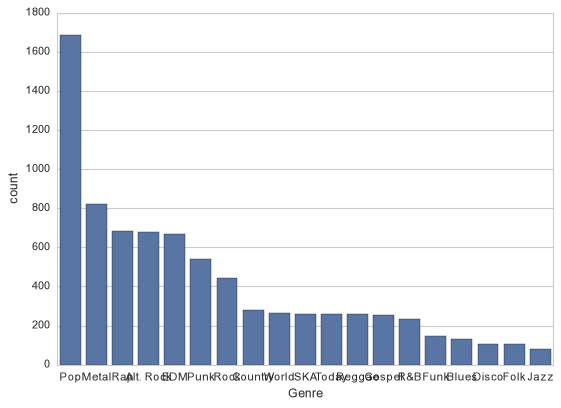

In [578]:


barrasa = df.value_counts("Genre")

sns.barplot(barrasa)

<Axes: xlabel='Genre', ylabel='count'>

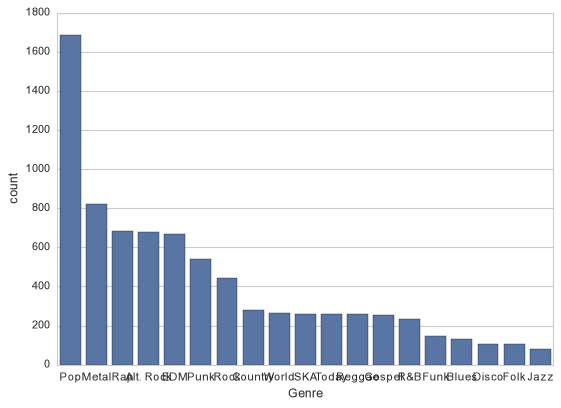

In [579]:
df = df[df["Year"] > 1980]
df = df[df["Year"] < 2020]
barras = df.value_counts("Genre")

sns.barplot(barras)

### Creamos una nueva categoría de géneros


Por un lado tendremos la categoría metal. Por el otro tenemos al Pop y a la música de hoy en dia


In [567]:

df["Genre2"] = np.select(
    [
        df["Genre"] == "Metal",
        df["Genre"].isin(["Pop", "Today"])
    ],
    [
        "Metal",
        "Pop/Today"
    ],
    default="Resto de géneros"
)


## Variables categoricas

In [568]:
df["Time_Signature"] = df["Time_Signature"].astype(str)
df["Key"] = df["Key"].astype(str)
df["Mode_ascat"] = df["Mode"].astype(str)

## Pasar las variables de la API de Spoty a escala 100
Las variabels de la API de spoty están pensandas para una maquina.
Para que sean más legible para los humanos lo multiplicaremos por 100.
Asi mismo nos da el tiempo en milisegundos. Por ello multiplicamos por mil y dividimos por 60. Así tenemos el tiempo en inteligibles minutos

In [569]:
#df = df[df["Genre"].isin(["Metal", "Punk","Alt. Rock","Rock"])]
#df = df[df["Genre"].isin(["Metal"])]

df["Duration"] = (df["Duration"]/1000) /60


df["Valence"] = df["Valence"] *100
df["Energy"] = df["Energy"] *100
df["Danceability"] = df["Danceability"] *100
df["Speechiness"] = df["Speechiness"] *100
df["Acousticness"] = df["Acousticness"] *100
df["Instrumentalness"] = df["Instrumentalness"] *100
df["Liveness"] = df["Liveness"] *100



## Inciamos lo descriptivo
### Mapa mediana variables api spoty

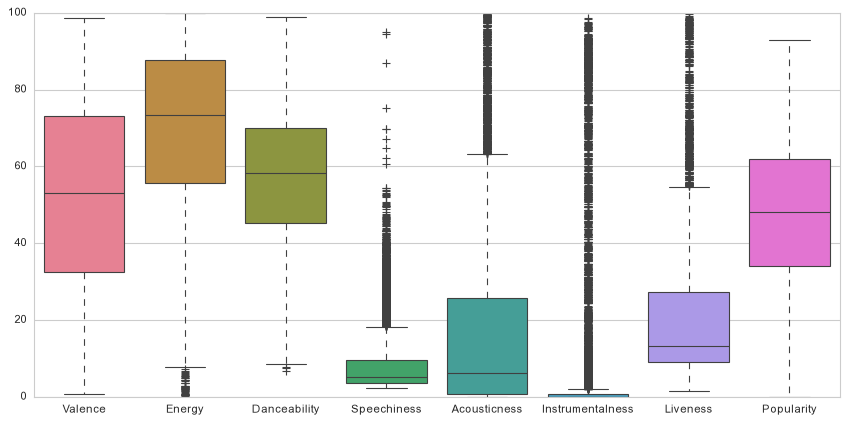

In [580]:
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.boxplot(data=df[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]])
plt.show()

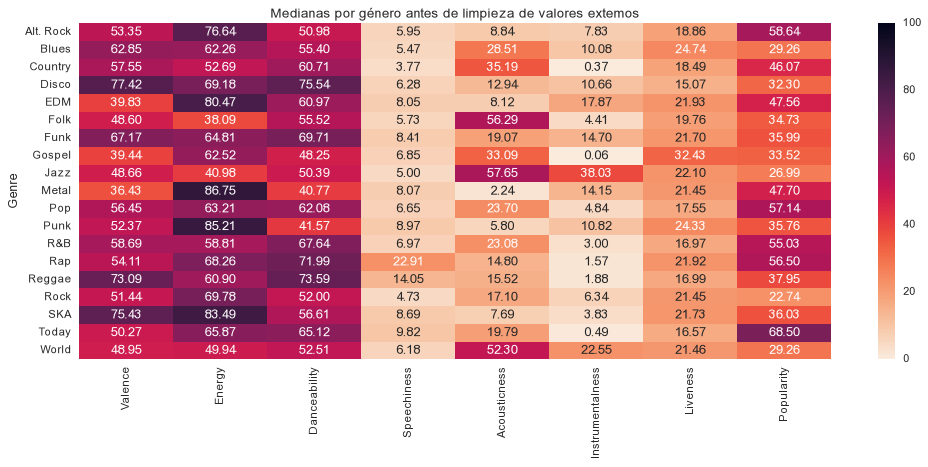

In [581]:
medianas = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por género antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

La calve de la canción parece no afectar a los criterios de la API de Spotify

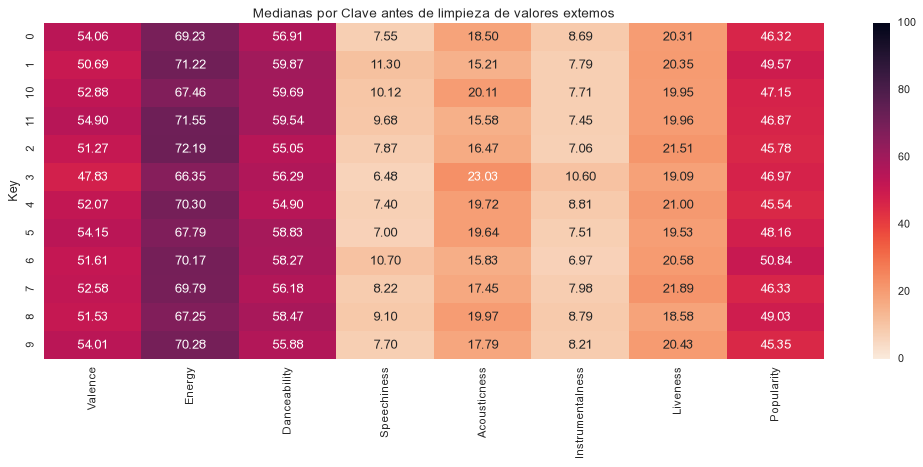

In [572]:
medianas = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por Clave antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

### Quitar valores extremos

In [573]:

#df = df[df["Duration"] < 10]
#df = df[df["Tempo"] > 50]
#df = df[df["Loudness"] > -15]
#df = df[df["Energy"] > 20]
#df = df[df["Instrumentalness"] < 1]
#df = df[df["Speechiness"] < 20]
#df = df[df["Liveness"] < 60]

df.info()



<class 'pandas.DataFrame'>
Index: 7899 entries, 0 to 15149
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             7899 non-null   str    
 1   Artist            7899 non-null   str    
 2   Year              7899 non-null   int64  
 3   Duration          7899 non-null   float64
 4   Time_Signature    7899 non-null   str    
 5   Danceability      7899 non-null   float64
 6   Energy            7899 non-null   float64
 7   Key               7899 non-null   str    
 8   Loudness          7899 non-null   float64
 9   Mode              7899 non-null   int64  
 10  Speechiness       7899 non-null   float64
 11  Acousticness      7899 non-null   float64
 12  Instrumentalness  7899 non-null   float64
 13  Liveness          7899 non-null   float64
 14  Valence           7899 non-null   float64
 15  Tempo             7899 non-null   float64
 16  Popularity        7899 non-null   int64  
 17  Genre     

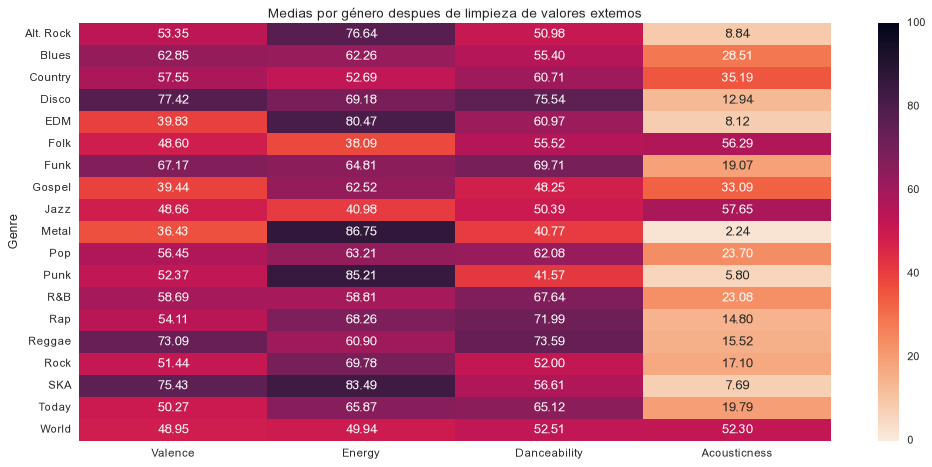

In [574]:
medias = df.groupby("Genre")[["Valence","Energy","Danceability","Acousticness"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medias,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)

plt.title("Medias por género despues de limpieza de valores extemos")
plt.tight_layout()
plt.show()

## Matriz de correlaciones

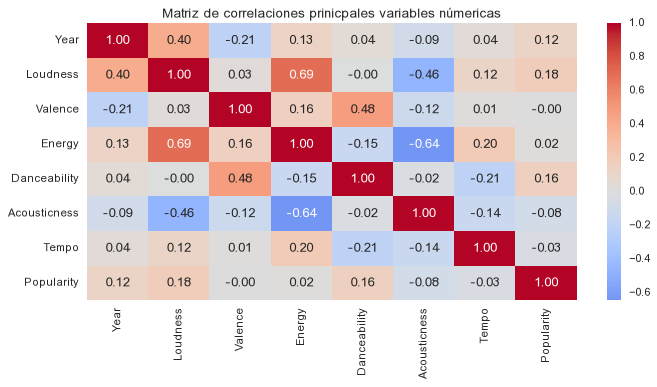

In [582]:
variables = [
    "Year",
    "Loudness",
    "Valence",
    "Energy",
    "Danceability",
    "Acousticness",
    "Tempo",
    "Popularity"
   
]

corr = df[variables].corr()

plt.figure(figsize=(9, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Matriz de correlaciones prinicpales variables númericas")
plt.tight_layout()
plt.show()

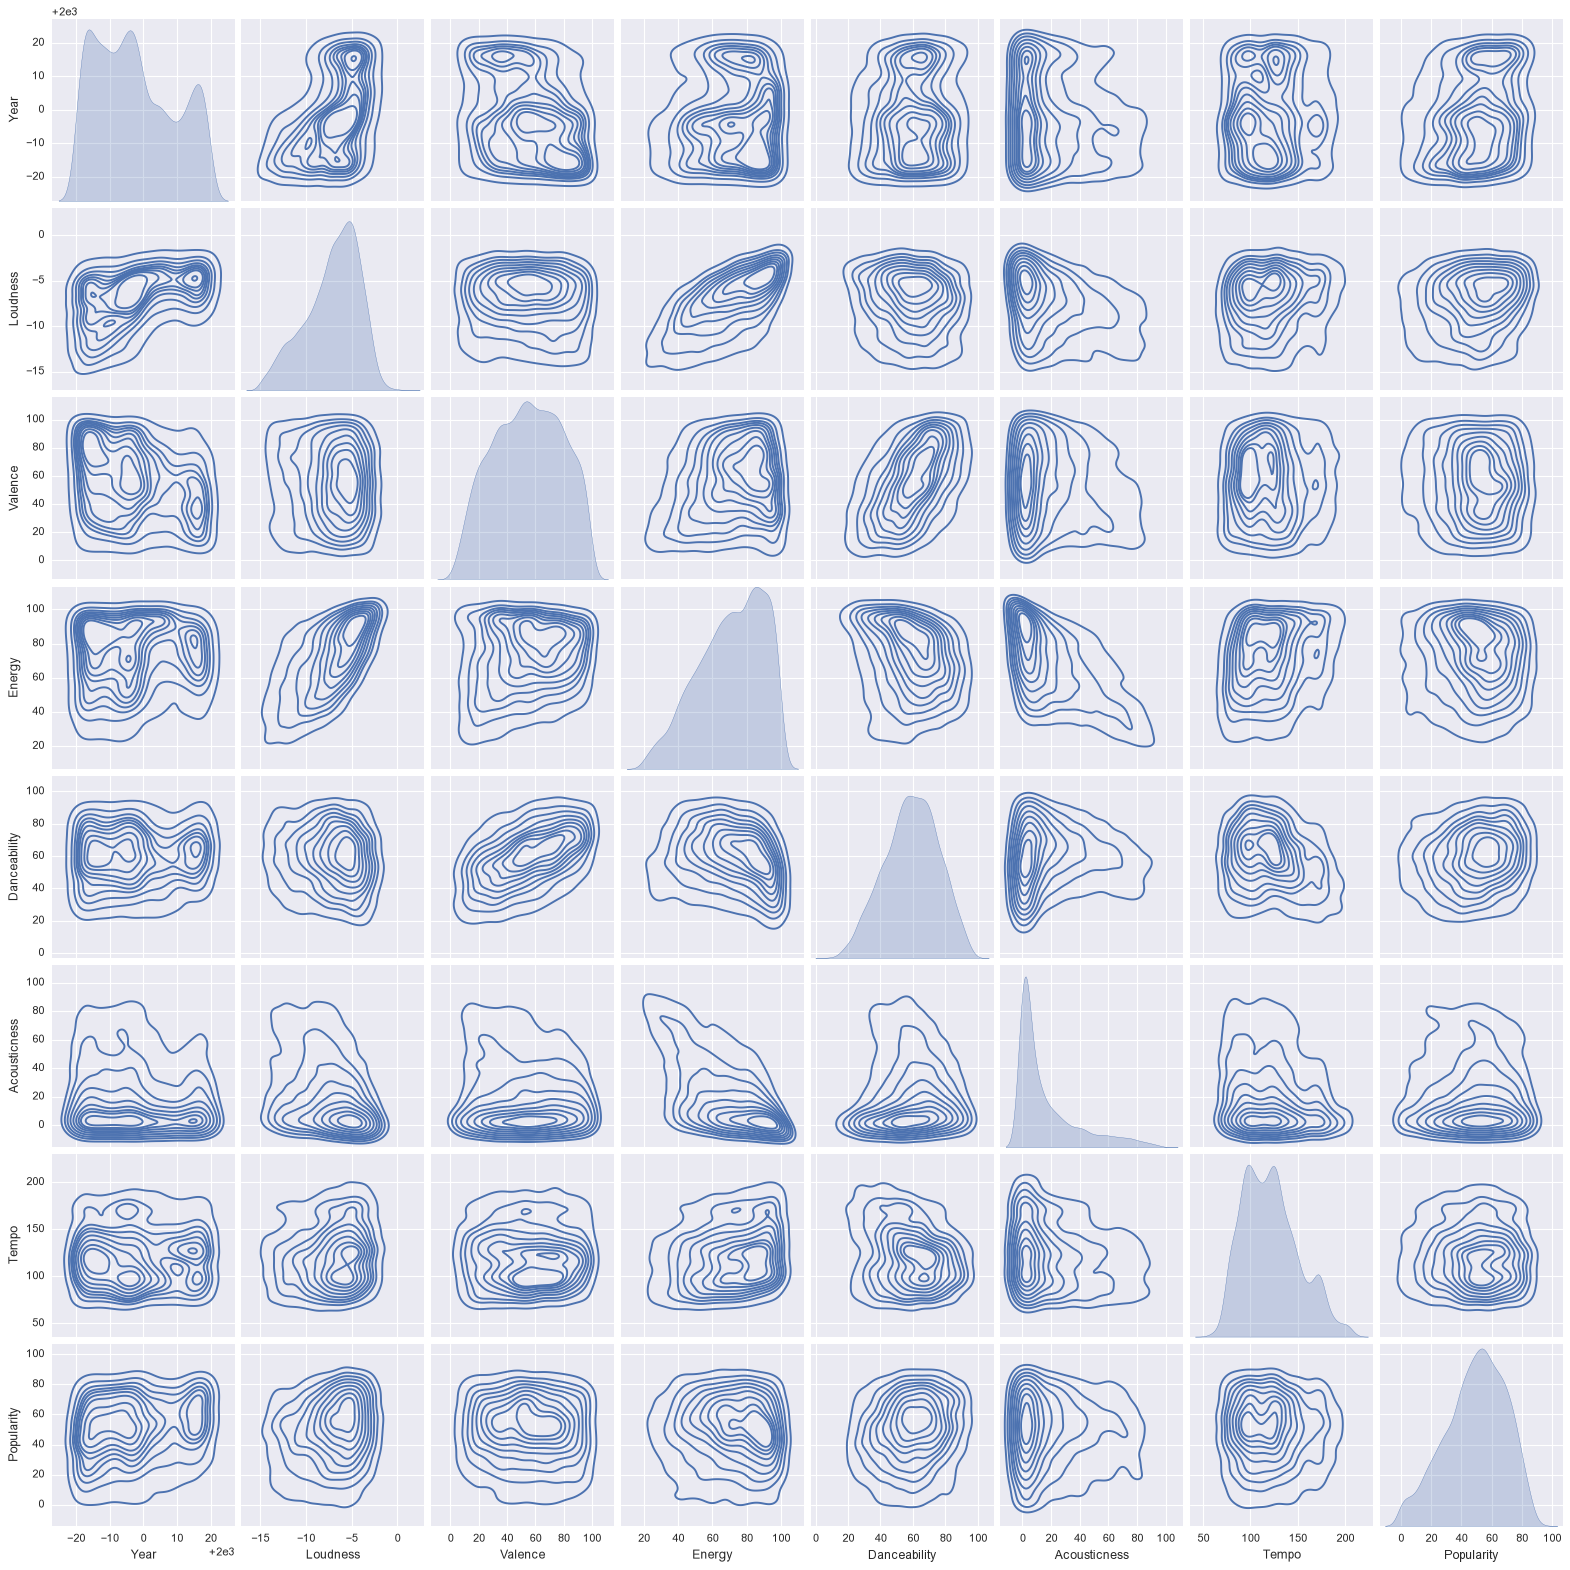

In [ ]:


#sns.pairplot(pd.DataFrame(df[variables]),kind ="kde")

### Loudness media a lo largo del tiempo

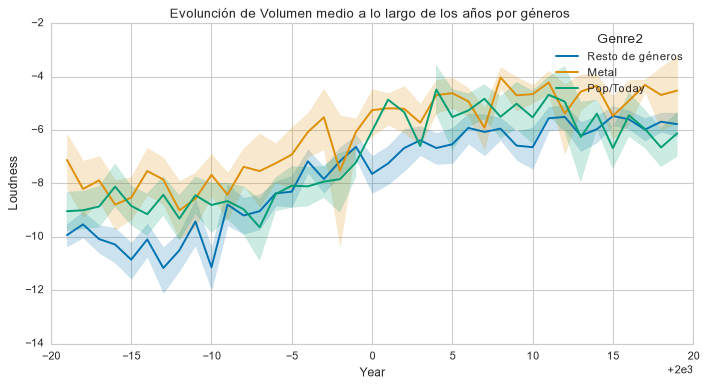

In [583]:
plt.figure(figsize=(9,5))



sns.lineplot(data = df, x = "Year", y = "Loudness", hue = "Genre2", palette = "colorblind")
plt.title("Evolunción de Volumen medio a lo largo de los años por géneros ")
plt.tight_layout()
plt.show()

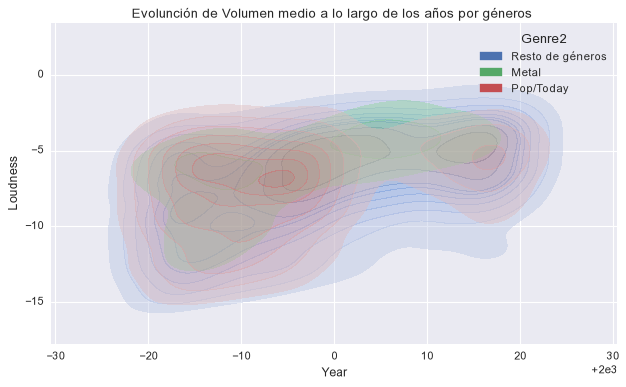

### Valence media a lo largo del tiempo

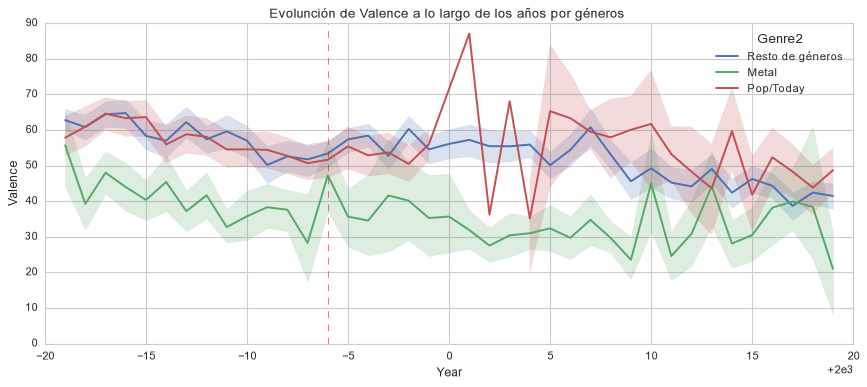

In [586]:

plt.figure(figsize=(11,5))

sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre2")
plt.title("Evolunción de Valence a lo largo de los años por géneros ")
plt.tight_layout()
plt.axvline(x=1994, color='red', linestyle='--', linewidth=0.5)

plt.show()

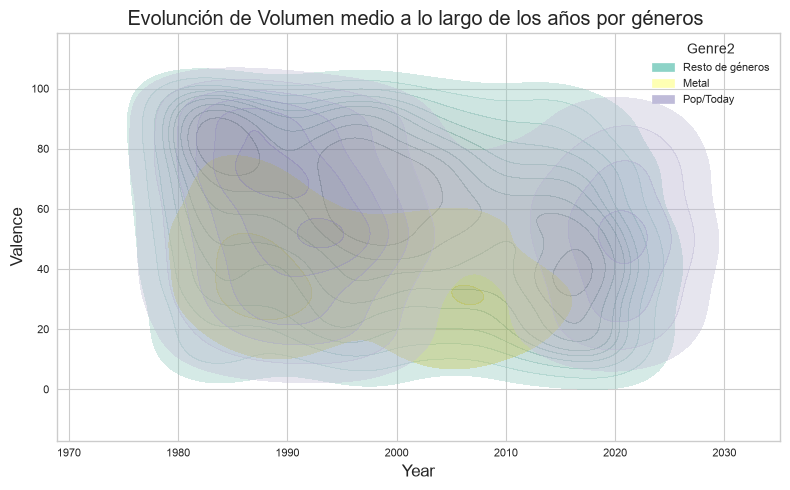

In [280]:
plt.figure(figsize=(8,5))

sns.kdeplot(data = df, x = "Year", y = "Valence", hue = "Genre2", alpha =0.4, fill = True)
plt.title("Evolunción de Volumen medio a lo largo de los años por géneros ")
plt.tight_layout()
plt.show()

En el caso del metal se observa una pequeña alza de la postividad de las canciones entre poco depspues del año 2000 y mediados de la década. Esto concuerda con un periodo sociohistorico muy concreto. El periodo entre el 11-S y el comienzo del hastío con la guera de Irak.

Para analizar como afecto este fénomeno a la producción músical analizaremos dos géneros contrapuestos el Country y el Punkk

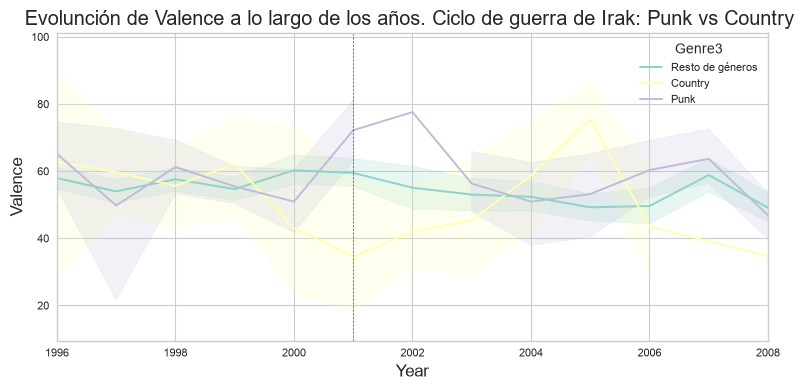

In [281]:

df["Genre3"] = np.select(
    [
        df["Genre"] == "Country",
        df["Genre"] == "Punk",

    
    ],
    [
        "Country",
        "Punk"

    ],
    default="Resto de géneros"
)
plt.figure(figsize=(8,4))
sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre3")
plt.xlim(1996, 2008)
plt.title("Evolunción de Valence a lo largo de los años. Ciclo de guerra de Irak: Punk vs Country ")
plt.tight_layout()
plt.axvline(x=2001, color='red', linestyle='--', linewidth=0.5)

plt.show()

s

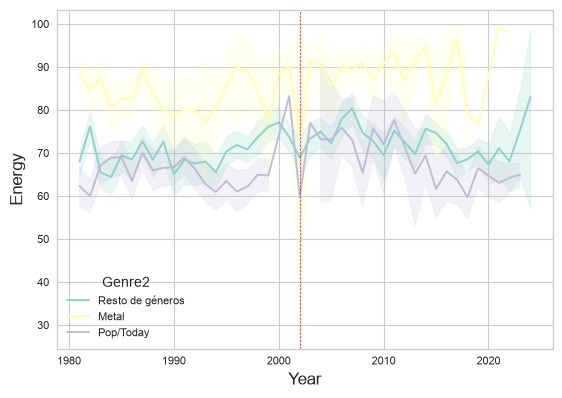

In [282]:
sns.lineplot(data = df, x = "Year", y = "Energy", hue = "Genre2")
plt.axvline(x=2002, color='red', linestyle='--', linewidth=0.5)




<Axes: xlabel='Year', ylabel='Tempo'>

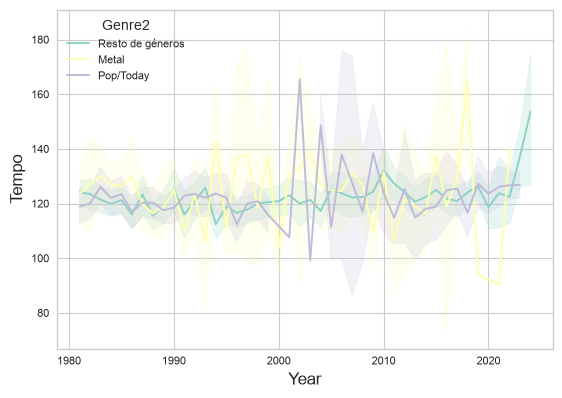

In [283]:
sns.lineplot(data = df, x = "Year", y = "Tempo", hue = "Genre2")


<Axes: xlabel='Year', ylabel='Danceability'>

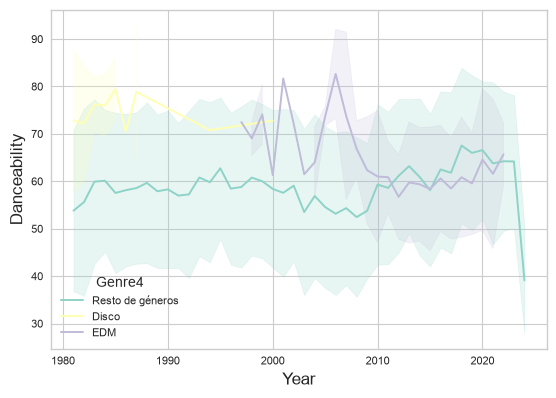

In [284]:
df["Genre4"] = np.select(
    [
        df["Genre"] == "Disco",
        df["Genre"].isin(["EDM"])
    ],
    [
        "Disco",
        "EDM"
    ],
    default="Resto de géneros"
)



sns.lineplot(data = df, x = "Year", y = "Danceability", hue = "Genre4", errorbar="sd")

# Popularidad y géneros

In [285]:

correlations = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Mode"])

    if p < 0.05:
        correlations.append({
            "Genre": genero,
            "Correlation": r
        })

# Crear DataFrame
corr_df = pd.DataFrame(correlations)

# Ordenar de mayor a menor correlación
corr_df = corr_df.sort_values("Correlation", ascending=False)

# Crear barplot
plt.figure(figsize=(12, 6))

sns.barplot(
    data=corr_df,
    x="Genre",
    y="Correlation",
    order=corr_df["Genre"],
    palette="viridis"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Correlación entre Modo y Popularidad")
plt.xlabel("Genre")
plt.ylabel("Pearson correlation (r)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

KeyError: 'Correlation'

correlación entre todos los generos y Loudness

In [ ]:
for genero, subset in df.groupby("Genre"):

    r, p = pearsonr(subset["Year"], subset["Loudness"])
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")


In [ ]:
for genero, subset in df.groupby("Genre"):

    r, p = pearsonr(subset["Valence"], subset["Energy"])
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

correlación entre todos los generos y Vicance

In [ ]:
for genero, subset in df.groupby("Genre"):

    r, p = pearsonr(subset["Popularity"], subset["Valence"])
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

correlación entre todos los generos y Vicance

In [ ]:
for genero, subset in df.groupby("Genre2"):

    r, p = pearsonr(subset["Year"], subset["Energy"])
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")


Danceability

In [ ]:


plt.figure(figsize=(7,4
                    ))  
sns.boxenplto(data =df,
            y = "Genre2",
            x= "Danceability",
            hue= "Genre2",
            alpha = 0.5)
plt.show()

Loudness

In [ ]:

plt.figure(figsize=(7,4
                    ))  
sns.boxenplot(data =df,
            y = "Genre2",
            x= "Loudness",
            hue= "Genre2")
plt.show()

In [ ]:

plt.figure(figsize=(7,4
                    ))  
sns.boxenplot(data =df,
            y = "Mode_ascat",
            x= "Valence",
            hue= "Mode_ascat")
plt.show()